# Weighted character co-occurrence network

This notebook builds an undirected NetworkX graph from resolved canonical character mentions grouped by paragraph. A paragraph contributes **one** to each unordered pair of distinct characters it contains, regardless of how often either character is mentioned there. For example, `A, A, B, C` contributes one each to A–B, A–C, and B–C; a paragraph containing only A contributes no edge.

Ground-truth characters are always included as graph nodes, even if they have no co-occurrences. Names are matched to node names and semicolon-separated aliases after trimming whitespace, case-folding, and removing accents. `Vilaça (pai)` is explicitly resolved to the ground-truth `vilaca_pai` node. `Dr. Guedes` and `Tobias` do not identify ground-truth nodes: to avoid losing their co-occurrences or inventing a ground-truth match, this notebook reports them and adds stable supplemental nodes. Any other unmatched or ambiguous names stop the export with a diagnostic.

Run all cells from the repository root in order (for example, in Jupyter choose **Kernel → Restart Kernel and Run All Cells**). The edge list is written to `Data/os_maias_cooccurrence_edges.csv`; it does not read or modify the manually curated `Data/os_maias_ground_truth_edges.csv`.

In [5]:
from collections import defaultdict
from itertools import combinations
from pathlib import Path
import unicodedata

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "Data"
paragraphs = pd.read_csv(DATA_DIR / "paragraphs.csv")
mentions = pd.read_csv(DATA_DIR / "mentions_characters.csv")
ground_truth_nodes = pd.read_csv(DATA_DIR / "os_maias_ground_truth_nodes.csv")

required_mention_columns = {"paragraph_id", "character"}
required_node_columns = {"id", "name", "aliases"}
if not required_mention_columns.issubset(mentions.columns):
    raise ValueError(f"Mentions file is missing columns: {required_mention_columns - set(mentions.columns)}")
if not required_node_columns.issubset(ground_truth_nodes.columns):
    raise ValueError(f"Ground-truth nodes file is missing columns: {required_node_columns - set(ground_truth_nodes.columns)}")
if mentions[["paragraph_id", "character"]].isna().any().any():
    raise ValueError("Mentions contain an empty paragraph_id or canonical character name.")

paragraph_ids = set(paragraphs["paragraph_id"])
unknown_paragraphs = set(mentions["paragraph_id"]) - paragraph_ids
if unknown_paragraphs:
    raise ValueError(f"Mentions refer to paragraph IDs absent from paragraphs.csv: {sorted(unknown_paragraphs)[:10]}")

print(f"Loaded {len(paragraphs):,} paragraphs, {len(mentions):,} resolved mentions, and {len(ground_truth_nodes):,} ground-truth nodes.")

Loaded 5,710 paragraphs, 6,114 resolved mentions, and 78 ground-truth nodes.


In [6]:
def normalize_name(value):
    """Normalize accents, case, and surrounding/repeated whitespace for matching."""
    decomposed = unicodedata.normalize("NFKD", str(value).strip())
    without_accents = "".join(char for char in decomposed if not unicodedata.combining(char))
    return " ".join(without_accents.casefold().split())


node_ids = set(ground_truth_nodes["id"].astype(str))
if len(node_ids) != len(ground_truth_nodes):
    raise ValueError("Ground-truth node IDs must be unique.")

alias_to_ids = defaultdict(set)
for row in ground_truth_nodes.itertuples(index=False):
    node_id = str(row.id)
    for label in [row.name, *str(row.aliases if pd.notna(row.aliases) else "").split(";")]:
        if str(label).strip():
            alias_to_ids[normalize_name(label)].add(node_id)

# This canonical label disambiguates Vilaça from Vilaça Júnior in the mention data.
MANUAL_CHARACTER_ID_OVERRIDES = {"Vilaça (pai)": "vilaca_pai"}
# These are intentionally supplemental rather than guessed ground-truth matches.
SUPPLEMENTAL_CHARACTER_IDS = {
    "Dr. Guedes": "unmatched_dr_guedes",
    "Tobias": "unmatched_tobias",
}

canonical_names = sorted(mentions["character"].astype(str).str.strip().unique())
character_to_id = {}
unmatched_names = []
ambiguous_names = {}
for canonical_name in canonical_names:
    if canonical_name in MANUAL_CHARACTER_ID_OVERRIDES:
        node_id = MANUAL_CHARACTER_ID_OVERRIDES[canonical_name]
        if node_id not in node_ids:
            raise ValueError(f"Manual mapping for {canonical_name!r} points to missing ground-truth ID {node_id!r}.")
        character_to_id[canonical_name] = node_id
        continue

    matches = alias_to_ids.get(normalize_name(canonical_name), set())
    if len(matches) == 1:
        character_to_id[canonical_name] = next(iter(matches))
    elif len(matches) > 1:
        ambiguous_names[canonical_name] = sorted(matches)
    elif canonical_name in SUPPLEMENTAL_CHARACTER_IDS:
        character_to_id[canonical_name] = SUPPLEMENTAL_CHARACTER_IDS[canonical_name]
    else:
        unmatched_names.append(canonical_name)

if ambiguous_names:
    raise ValueError(f"Ambiguous canonical character mappings; resolve explicitly before exporting: {ambiguous_names}")
if unmatched_names:
    raise ValueError(
        "Canonical character names have no ground-truth mapping or explicit supplemental ID. "
        f"Add a reviewed mapping before exporting: {unmatched_names}"
    )

supplemental_names = sorted(SUPPLEMENTAL_CHARACTER_IDS)
supplemental_ids = set(SUPPLEMENTAL_CHARACTER_IDS.values())
if supplemental_ids & node_ids or len(supplemental_ids) != len(SUPPLEMENTAL_CHARACTER_IDS):
    raise ValueError("Supplemental IDs must be unique and must not collide with ground-truth IDs.")

mentions = mentions.copy()
mentions["character_id"] = mentions["character"].astype(str).str.strip().map(character_to_id)
if mentions["character_id"].isna().any():
    raise ValueError("At least one mention did not receive a node ID; refusing to build an incomplete network.")

print("Explicit canonical-name resolutions:", MANUAL_CHARACTER_ID_OVERRIDES)
print("Reported unmatched canonical names preserved as supplemental nodes:", SUPPLEMENTAL_CHARACTER_IDS)
print(f"Ground-truth canonical names matched through names/aliases: {len(canonical_names) - len(MANUAL_CHARACTER_ID_OVERRIDES) - len(supplemental_names)}")

Explicit canonical-name resolutions: {'Vilaça (pai)': 'vilaca_pai'}
Reported unmatched canonical names preserved as supplemental nodes: {'Dr. Guedes': 'unmatched_dr_guedes', 'Tobias': 'unmatched_tobias'}
Ground-truth canonical names matched through names/aliases: 56


In [7]:
def count_paragraph_cooccurrences(frame):
    """Count each unordered pair once per paragraph, after deduplicating characters."""
    edge_weights = defaultdict(int)
    for _, group in frame.groupby("paragraph_id", sort=False):
        distinct_ids = sorted(set(group["character_id"]))
        for left, right in combinations(distinct_ids, 2):
            edge_weights[(left, right)] += 1
    return dict(edge_weights)


example = pd.DataFrame({
    "paragraph_id": [1, 1, 1, 1, 2],
    "character_id": ["A", "A", "B", "C", "A"],
})
expected = {("A", "B"): 1, ("A", "C"): 1, ("B", "C"): 1}
assert count_paragraph_cooccurrences(example) == expected
print("Counting example passed: A twice, B and C once gives one per pair; singleton A gives no edge.")

Counting example passed: A twice, B and C once gives one per pair; singleton A gives no edge.


In [8]:
edge_weights = count_paragraph_cooccurrences(mentions)
G = nx.Graph()

for row in ground_truth_nodes.itertuples(index=False):
    G.add_node(
        str(row.id),
        name=str(row.name),
        role_or_group=row.role_or_group,
        aliases=row.aliases,
        node_type="ground_truth",
    )
for canonical_name, node_id in SUPPLEMENTAL_CHARACTER_IDS.items():
    G.add_node(node_id, name=canonical_name, node_type="supplemental_unmatched")
for (source, target), weight in edge_weights.items():
    G.add_edge(source, target, weight=int(weight))

export_edges = pd.DataFrame(
    sorted(
        ((min(source, target), max(source, target), int(data["weight"]))
         for source, target, data in G.edges(data=True)),
        key=lambda edge: (edge[0], edge[1]),
    ),
    columns=["source", "target", "weight"],
)
output_path = DATA_DIR / "os_maias_cooccurrence_edges.csv"
export_edges.to_csv(output_path, index=False)
print(f"Exported {len(export_edges):,} weighted edges to {output_path.relative_to(PROJECT_DIR)}")

Exported 367 weighted edges to Data\os_maias_cooccurrence_edges.csv


In [9]:
exported = pd.read_csv(output_path)
assert list(exported.columns) == ["source", "target", "weight"]
assert set(exported["source"]).issubset(G.nodes) and set(exported["target"]).issubset(G.nodes)
assert (exported["source"] != exported["target"]).all()
assert (exported["weight"] > 0).all()
assert pd.api.types.is_integer_dtype(exported["weight"])
assert not exported.duplicated(["source", "target"]).any()
assert len(G.nodes) == len(ground_truth_nodes) + len(SUPPLEMENTAL_CHARACTER_IDS)
assert set(ground_truth_nodes["id"].astype(str)).issubset(G.nodes)
assert len(exported) == G.number_of_edges()
print(
    f"Validated {len(exported):,} edges: positive integer weights, unique unordered pairs, "
    f"and source/target IDs present in the {len(G):,}-node graph."
)
print(f"Isolates retained: {sum(degree == 0 for _, degree in G.degree())}")

Validated 367 edges: positive integer weights, unique unordered pairs, and source/target IDs present in the 80-node graph.
Isolates retained: 22


Graph summary: 80 nodes, 367 edges
Supplemental unmatched nodes: ['Dr. Guedes', 'Tobias']
Maximum edge weight (paragraphs): 327


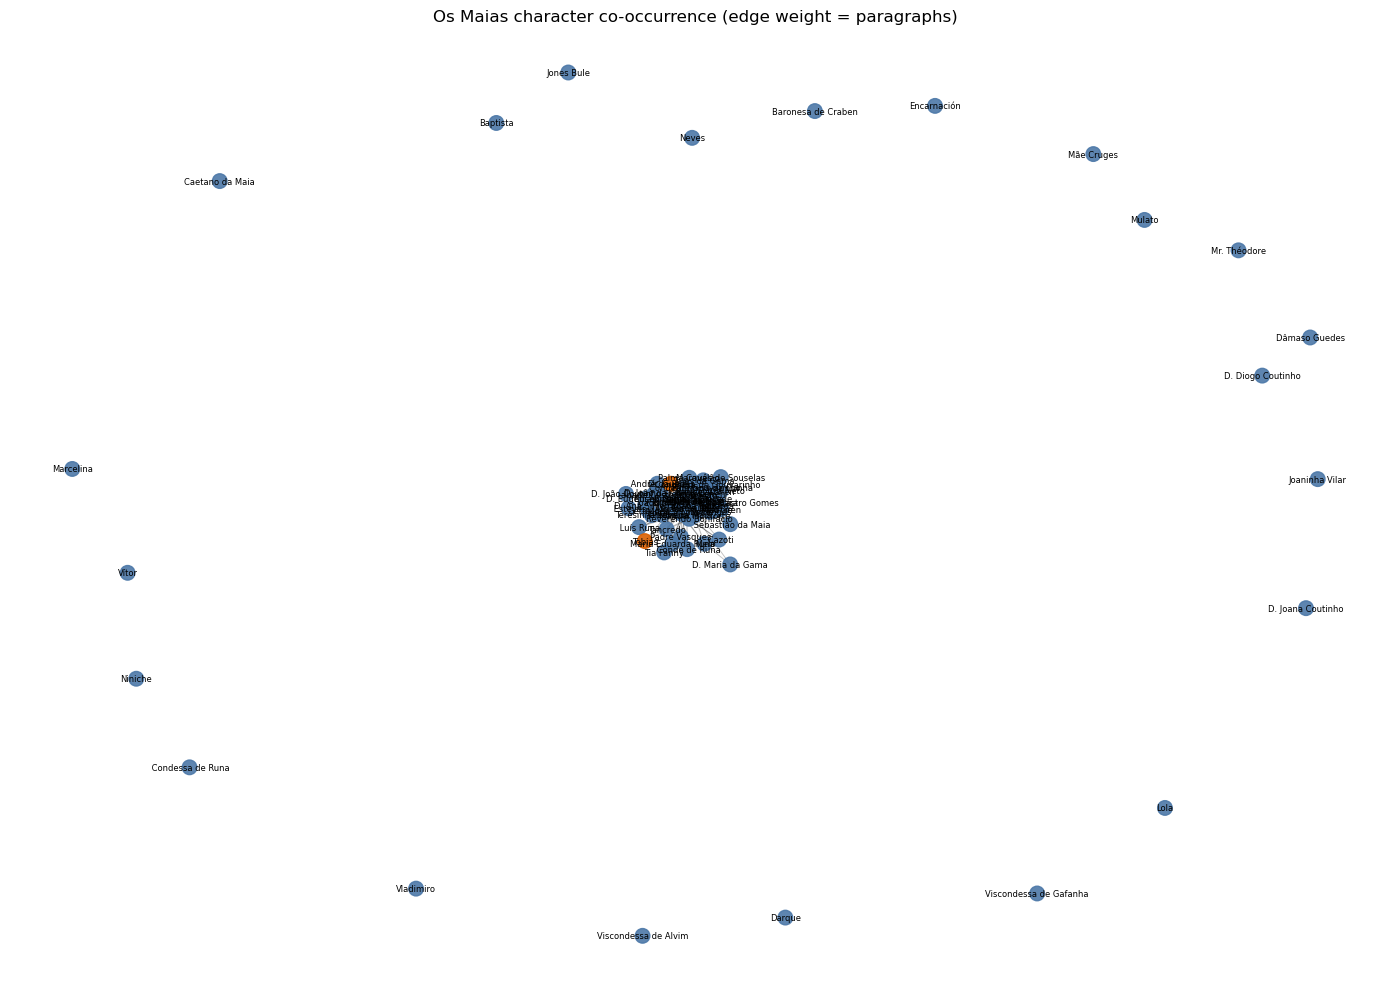

In [10]:
print(f"Graph summary: {G.number_of_nodes():,} nodes, {G.number_of_edges():,} edges")
print(f"Supplemental unmatched nodes: {supplemental_names}")
print(f"Maximum edge weight (paragraphs): {max((data['weight'] for _, _, data in G.edges(data=True)), default=0)}")

plt.figure(figsize=(14, 10))
positions = nx.spring_layout(G, seed=42, weight="weight")
node_colors = [
    "#d95f02" if G.nodes[node]["node_type"] == "supplemental_unmatched" else "#4c78a8"
    for node in G.nodes
]
edge_widths = [0.4 + 0.25 * G[u][v]["weight"] ** 0.5 for u, v in G.edges]
nx.draw_networkx_edges(G, positions, width=edge_widths, alpha=0.25)
nx.draw_networkx_nodes(G, positions, node_color=node_colors, node_size=110, alpha=0.9)
nx.draw_networkx_labels(
    G, positions,
    labels={node: G.nodes[node]["name"] for node in G},
    font_size=6,
)
plt.title("Os Maias character co-occurrence (edge weight = paragraphs)")
plt.axis("off")
plt.tight_layout()
plt.show()